In [123]:
import tensorflow as tf
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models, Input, Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import Sequence

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, average_precision_score
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, jaccard_score
from sklearn.metrics import precision_recall_curve

SEED = 1234
tf.keras.utils.set_random_seed(SEED)        
tf.config.experimental.enable_op_determinism()

## Uploading the Data

This section was edited from the original to load the data using the same method as in my trial.

In [124]:
DATA_PATH = '/Users/jordanagresti/Desktop/Data Projects/Wildfire/Original Project/aria_preprocessed_data/'
RUN_DIR = '/Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/'
os.makedirs(RUN_DIR, exist_ok=True)

In [125]:
INPUT_FEATURES = ['tmmn', 'tmmx', 'th', 'vs', 'pr', 'sph',
                  'pdsi', 'NDVI', 'erc', 'population', 'elevation', 'PrevFireMask']
GRID_SIZE = 64

In [126]:
files = os.listdir(DATA_PATH)
print(f'Found {len(files)} files:')
for file in files:
    print(file)

Found 7 files:
.DS_Store
Y_train.npy
Y_test.npy
X_test.npy
Y_val.npy
X_train.npy
X_val.npy


In [127]:
X_train = np.load(DATA_PATH + 'X_train.npy')
Y_train = np.load(DATA_PATH + 'Y_train.npy')
X_val   = np.load(DATA_PATH + 'X_val.npy')
Y_val   = np.load(DATA_PATH + 'Y_val.npy')
X_test  = np.load(DATA_PATH + 'X_test.npy')
Y_test  = np.load(DATA_PATH + 'Y_test.npy')

for name, arr in [('X_train', X_train), ('Y_train', Y_train), ('X_val', X_val),
                  ('Y_val', Y_val), ('X_test', X_test), ('Y_test', Y_test)]:
    print(f"{name}: shape={arr.shape}, min={arr.min():.3f}, max={arr.max():.3f}")

X_train: shape=(14979, 64, 64, 12), min=-147.310, max=126.392
Y_train: shape=(14979, 64, 64), min=-1.000, max=1.000
X_val: shape=(1877, 64, 64, 12), min=-29.650, max=126.392
Y_val: shape=(1877, 64, 64), min=-1.000, max=1.000
X_test: shape=(1689, 64, 64, 12), min=-99.278, max=111.222
Y_test: shape=(1689, 64, 64), min=-1.000, max=1.000


Below is the function `build_combined_target`. This function creates one combined target array per split. For example:
- `combined[..., 0] = label` (dummy 0 where invalid)
- `combined[..., 1] = weight` (0 = ignore, pos_weight = fire, 1 = no-fire)
This function was created to manange memory issues due to Google Colab's limited RAM.

In [128]:
def build_combined_target(Y, pos_weight):
    Y = Y.astype(np.float32)
    label = np.where(Y == -1, 0.0, Y).astype(np.float32)
    weight = np.where(Y == -1, 0.0, np.where(Y == 1, pos_weight, 1.0)).astype(np.float32)
    return np.stack([label, weight], axis=-1)  # shape (N, 64, 64, 2)

n_fire = (Y_train == 1).sum()
n_nofire = (Y_train == 0).sum()
pos_weight = n_nofire / n_fire
print(f"pos_weight: {pos_weight:.2f}")

target_train = build_combined_target(Y_train, pos_weight)
target_val   = build_combined_target(Y_val, pos_weight)
target_test  = build_combined_target(Y_test, pos_weight)

# Delete the old Y datasets (as we created new ones above)
del Y_train, Y_val, Y_test
import gc; gc.collect()

print("target_train shape:", target_train.shape, "(expect N,64,64,2)")

pos_weight: 90.02
target_train shape: (14979, 64, 64, 2) (expect N,64,64,2)


In [129]:
# added for evaluation comparison
def plot_loss_curves(history, title):
    h = history.history
    epochs = range(1, len(h['loss']) + 1)
    best = int(np.argmin(h['val_loss'])) + 1          # epoch that early stopping restored
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, h['loss'], 'o-', label='train')
    plt.plot(epochs, h['val_loss'], 'o-', label='validation')
    plt.axvline(best, ls='--', color='grey', label=f'best epoch ({best})')
    plt.xlabel('epoch'); plt.ylabel('masked weighted BCE')
    plt.title(f'{title}: loss curves'); plt.grid(alpha=.3); plt.legend(); plt.show()

def best_f1_threshold(y_true, y_score):
    p, r, t = precision_recall_curve(y_true, y_score)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-10)
    return t[np.argmax(f1)]

CM_LABELS = np.array([['TN', 'FP'],      # new: matches sklearn's layout
                      ['FN', 'TP']])     # rows = true class, columns = predicted class

def add_cm_labels(disp):                 # new
    for i in range(2):
        for j in range(2):
            text = disp.text_[i, j]
            text.set_text(f"{CM_LABELS[i, j]}\n{text.get_text()}")

def plot_confusion(y_true, y_score, threshold, title):
    y_true = y_true.astype(int)
    y_pred = (y_score >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

    disp = ConfusionMatrixDisplay(cm, display_labels=['no fire', 'fire']).plot(
        ax=axs[0], values_format=',', colorbar=False)
    add_cm_labels(disp)                  # new
    axs[0].set_title('Counts')

    disp = ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True),
                                  display_labels=['no fire', 'fire']).plot(
        ax=axs[1], values_format='.3f', colorbar=False)
    add_cm_labels(disp)                  # new
    axs[1].set_title('Share of each true class')

    fig.suptitle(f'{title} (threshold = {threshold:.3f}, valid pixels only)')
    plt.tight_layout(); plt.show()
    print(f"PR-AUC: {average_precision_score(y_true, y_score):.4f}")


results = []   

def summarize(model, split, y_true, y_score, threshold):
    y_true = y_true.astype(int)
    y_pred = (y_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return dict(model=model, split=split, threshold=threshold,
                pr_auc=average_precision_score(y_true, y_score),
                roc_auc=roc_auc_score(y_true, y_score),
                precision=precision, recall=recall, f1=f1,
                iou=tp / (tp + fp + fn))

## Building the Baseline Model

This baseline model is equivalent to a 1x1 Convolutional Neural Network, which is equivalent to a logistic regression model. For this model, and the two improvements, we are using a Binary Cross-Entropy (BCE) loss function. While running the model, we found that simply selecting BCE as the loss function kept causing the Google Colab kernel to crash. So, due to the limited memory of Google Colab, we created the function `masked_weighted_bce`. This function accomplishes two things while computing BCE loss:
- Ignores invalid pixels (Y values = -1) 
- "Upweights" the fire-pixel class (due to how rare it is) so the model doesn't just learn to always predict "no fire".

Furthermore, the baseline model is also created below. For this simple model, we use the custom loss function, the Adam optimizer, a learning rate of 1e-3, and a batch size of 32. We also set the number of epochs to 50 but include an early stopping callback: `val_loss` is monitored with a patience of 5 epochs. 

In [130]:
# Loss function
def masked_weighted_bce(y_true, y_pred):
    label  = y_true[..., 0:1]
    weight = y_true[..., 1:2]
    y_pred = tf.sigmoid(y_pred)
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
    bce = -(label * tf.math.log(y_pred) + (1 - label) * tf.math.log(1 - y_pred))
    weighted = bce * weight
    return tf.reduce_sum(weighted) / (tf.reduce_sum(weight) + 1e-7)

# Baseline model
def build_baseline_model():
    inputs = layers.Input(shape=(GRID_SIZE, GRID_SIZE, len(INPUT_FEATURES)))
    outputs = layers.Conv2D(1, 1, activation=None, padding='same')(inputs)
    return models.Model(inputs, outputs, name='baseline_1x1_cnn')

tf.keras.utils.set_random_seed(SEED)
tf.keras.backend.clear_session()
baseline_model = build_baseline_model()
baseline_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=masked_weighted_bce)
print(f"Trainable params: {baseline_model.count_params()} (expect 13)")

Trainable params: 13 (expect 13)


Below is a class called `ArraySequence`. This class was created due to memory issues with Google Colab. It subclasses Keras's `Sequence` to create a custom generator that pulls batches directly from the existing in-memory NumPy arrays (X and y) via index slicing in `__getitem__`. This is done rather than trying to load the full dataset, which doesn't fit in the 12GB RAM of Google Colab. 

This class also handles shuffling (between individual datasets) manually. The function `on_epoch_end` reshuffles `self.indices` after each epoch completes. So, each epoch sees a completely different random ordering of batches. If this shuffling did not happen, the model would see the exact same batch groupings every epoch, which could lead the model to partially memorizing batch-level patterns rather than generalizing.

Also note that only the training data is shuffled; the validation data is not shuffled because its purpose is only for measuring performance, not learning.

In [131]:
class ArraySequence(Sequence):
    """Batches directly from existing numpy arrays — no copying, no tf.data shuffle buffer."""
    def __init__(self, X, y, batch_size, shuffle=True, **kwargs):
        super().__init__(**kwargs)
        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(X))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.X) / self.batch_size))

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        return self.X[batch_idx], self.y[batch_idx]

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

# Build train/val generators
train_gen = ArraySequence(X_train, target_train, batch_size=8, shuffle=True)
val_gen = ArraySequence(X_val, target_val, batch_size=8, shuffle=False)

print(f"Train batches per epoch: {len(train_gen)}")
print(f"Val batches per epoch: {len(val_gen)}")

Train batches per epoch: 1873
Val batches per epoch: 235


In [132]:
# Create the early stopping callback
early_stop_baseline = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True, verbose=1
)

# Checkpoint path
baseline_checkpoint_path = RUN_DIR + 'baseline_1x1_cnn_best.keras'

checkpoint_baseline = ModelCheckpoint(
    filepath=baseline_checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [133]:
# Run the baseline model
history_baseline = baseline_model.fit(
    train_gen,
    validation_data=val_gen,
    batch_size=32, epochs=50,
    callbacks=[early_stop_baseline, checkpoint_baseline],
    verbose=1
)
pd.DataFrame(history_baseline.history).to_csv(RUN_DIR + 'history_baseline.csv', index=False)

Epoch 1/50
1868/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6297
Epoch 1: val_loss improved from None to 0.59820, saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/baseline_1x1_cnn_best.keras

Epoch 1: finished saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/baseline_1x1_cnn_best.keras
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.6295 - val_loss: 0.5982
Epoch 2/50
1865/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5606
Epoch 2: val_loss improved from 0.59820 to 0.59098, saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/baseline_1x1_cnn_best.keras

Epoch 2: finished saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/baseline_1x1_cnn_best.keras
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.5605 - val_loss: 0.5910
Epoch 3/50
1845/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5567
Epoch 3: val_loss improved from 0.59098 to 0.59057, saving model to /Users/j

Below, the baseline model is evaluated using a few metrics: AUC (Area Under the Curve), Precision, Recall, F1, and IoU (Intersection over Union). Note that we are mainly focusing on how AUC turns out. This is due to the severe class-imbalance of 90:1 of no-fire to fire pixels in the data. AUC evaluates the model's performance across all possible decision thresholds, making it effectively threshold-dependent. So, AUC offers the most truthful look at how well the model is performing.

The metrics are all computed using `scikit-learn`'s various packages (listed in the Imports).

In [134]:
# Load the saved baseline checkpoint
baseline_checkpoint_path = RUN_DIR + 'baseline_1x1_cnn_best.keras'
baseline_model = tf.keras.models.load_model(
    baseline_checkpoint_path,
    custom_objects={'masked_weighted_bce': masked_weighted_bce}
)

# Get predictions
val_preds = baseline_model.predict(X_val, batch_size=64, verbose=1)

# Extract label and weight/mask channels from target_val
val_labels = target_val[..., 0]   # (N, 64, 64)
val_weights = target_val[..., 1]  
val_preds_flat = tf.sigmoid(val_preds[..., 0]).numpy()

# Build valid-pixel mask (weight > 0 means it was NOT an uncertain -1 pixel)
valid_mask = val_weights > 0

# Flatten and filter to valid pixels only
y_true = val_labels[valid_mask]
y_score = val_preds_flat[valid_mask]
y_pred_binary = (y_score >= 0.5).astype(int)

print(f"Valid pixels evaluated: {valid_mask.sum():,} / {valid_mask.size:,}")
print(f"Fire pixel rate among valid: {y_true.mean() * 100:.2f}%")

# Compute metrics
auc = roc_auc_score(y_true, y_score)
pr_auc = average_precision_score(y_true, y_score)
precision = precision_score(y_true, y_pred_binary, zero_division=0)
recall = recall_score(y_true, y_pred_binary, zero_division=0)
f1 = f1_score(y_true, y_pred_binary, zero_division=0)

# IoU computed manually (intersection over union for the fire class)
intersection = np.logical_and(y_true == 1, y_pred_binary == 1).sum()
union = np.logical_or(y_true == 1, y_pred_binary == 1).sum()
iou = intersection / union if union > 0 else 0.0

print("\n---Baseline (1x1 CNN) Validation Metrics---")
print(f"AUC:       {auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1:        {f1:.4f}")
print(f"IoU:       {iou:.4f}")

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


E0000 00:00:1793313607.797064 91918165 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Valid pixels evaluated: 7,500,385 / 7,688,192
Fire pixel rate among valid: 1.37%

---Baseline (1x1 CNN) Validation Metrics---
AUC:       0.7363
PR-AUC:    0.0846
Precision: 0.0282
Recall:    0.5438
F1:        0.0537
IoU:       0.0276


From the metrics above, we see that AUC is very moderate at about 0.7252 and recall is the next highest metric at 0.2495. The other metrics, such as precision, F1, and IoU are all quite low, and this may be due to the severe class imbalance between no-fire/fire pixels. To improve upon this AUC score, we now build a multi-layer CNN.

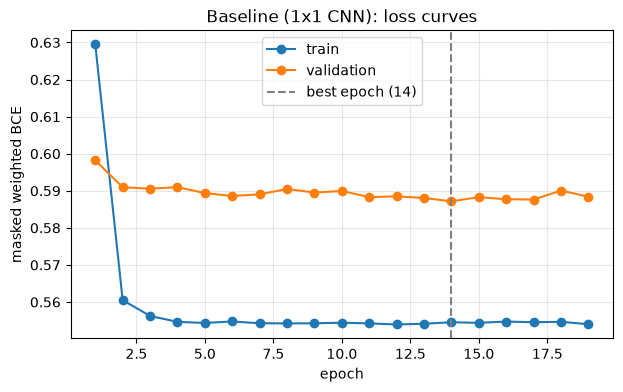

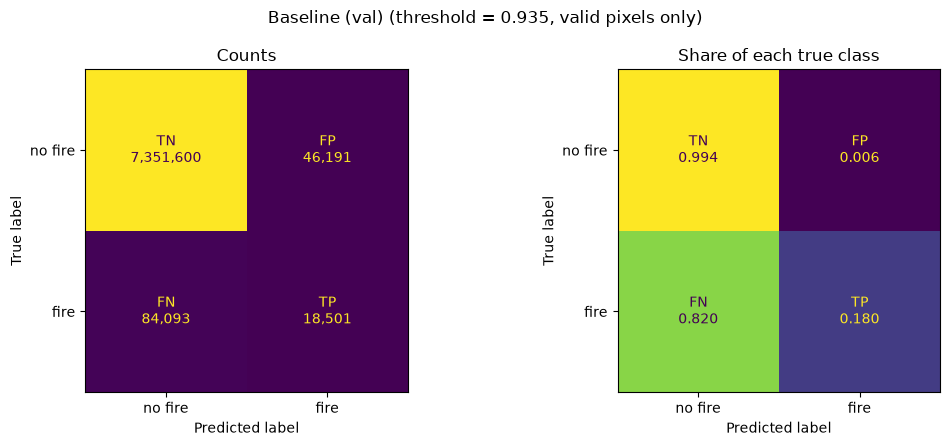

PR-AUC: 0.0846


In [135]:
plot_loss_curves(history_baseline, 'Baseline (1x1 CNN)')
plot_confusion(y_true, y_score, best_f1_threshold(y_true, y_score), 'Baseline (val)')
results.append(summarize('Baseline', 'val', y_true, y_score, best_f1_threshold(y_true, y_score)))

## Building Model 2: Multi-Layer CNN

Below, the second model is built, which is a Multi-Layer Convolutional Neural Network (CNN). This model has three convolutional layers, each with a kernel size of 3x3, and the first layers have 32 filters, while the third has 16 layers. Each of these layers using the `ReLU` activation function. The output contains logits rather than probabilities. This is due to the fact that logits keep the output raw and unbounded, rather than smushing it between 0 and 1. 

The summary of the model is displayed below.

In [136]:
# Get model parameters
def build_multilayer_cnn(input_shape=(64, 64, 12)):
    inputs = Input(shape=input_shape, name='features')

    x = layers.Conv2D(32, 3, padding='same', activation='relu', name='conv1')(inputs)
    x = layers.Conv2D(32, 3, padding='same', activation='relu', name='conv2')(x)
    x = layers.Conv2D(16, 3, padding='same', activation='relu', name='conv3')(x)
    outputs = layers.Conv2D(1, 1, padding='same', activation=None, name='logits')(x)

    return Model(inputs, outputs, name='multilayer_cnn')

tf.keras.utils.set_random_seed(SEED)
tf.keras.backend.clear_session()
multilayer_model = build_multilayer_cnn()
multilayer_model.summary()

Model: "multilayer_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 64, 64, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │         3,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 64, 64, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Conv2D)                 │ (None, 64, 64, 1)      │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,377 (67.88 KB)

 Trainable params: 17,377 (67.88 KB)

 Non-trainable params: 0 (0.00 B)

The model is compiled below. Note that we are still using the Adam optimizer, a learning rate of 1e-3, and the `masked_weighted_bce` function created towards the beginning of the notebook.

In [137]:
# Compiling the model
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

multilayer_model.compile(
    optimizer=optimizer,
    loss=masked_weighted_bce
)

Some callbacks are declared below. Once again, `EarlyStopping` is used to monitor `val_loss` with a patience of 5 epochs. A `ModelCheckpoint` is also used to save the best weights in a directory in Google Drive. This is also monitoring `val_loss`.

In [138]:
# Declare necessary callbacks for the model
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath= RUN_DIR + 'multilayer_cnn_best.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

The multilayer CNN, Model 2, is run below. It uses the training and validation generators created above and it set for 30 epochs. Note the `EarlyStopping` and `ModelCheckpoint` callbacks are present, as well.

In [139]:
# Run the model
history_multilayer = multilayer_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    callbacks=callbacks,
    verbose=1
)
pd.DataFrame(history_multilayer.history).to_csv(RUN_DIR + 'history_multilayer.csv', index=False)

Epoch 1/30
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.4347
Epoch 1: val_loss improved from None to 0.49185, saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/multilayer_cnn_best.keras

Epoch 1: finished saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/multilayer_cnn_best.keras
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 50s 26ms/step - loss: 0.4347 - val_loss: 0.4918
Epoch 2/30
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.3929
Epoch 2: val_loss did not improve from 0.49185
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 48s 26ms/step - loss: 0.3929 - val_loss: 0.5191
Epoch 3/30
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.3815
Epoch 3: val_loss did not improve from 0.49185
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 48s 26ms/step - loss: 0.3815 - val_loss: 0.5032
Epoch 4/30
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.3769
Epoch 4: val_loss did not improve from 0.49185
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 49s 26ms/step - loss: 0.3769 - val_

In [140]:
# Load the multilayer CNN checkpoint path
multilayer_checkpoint_path = RUN_DIR + 'multilayer_cnn_best.keras'
multilayer_model = tf.keras.models.load_model(
    multilayer_checkpoint_path,
    custom_objects={'masked_weighted_bce': masked_weighted_bce}
)

# Predict logits, convert to probabilities
val_logits = multilayer_model.predict(X_val, batch_size=32, verbose=1)
val_probs = tf.sigmoid(val_logits).numpy().squeeze(-1)  # (N,64,64)

# Recover labels + valid mask from target_val
val_labels = target_val[..., 0]
val_weights = target_val[..., 1]
valid_mask = val_weights > 0 

# Flatten to valid pixels only
y_true = val_labels[valid_mask]
y_score = val_probs[valid_mask]

# AUC score
auc = roc_auc_score(y_true, y_score)
pr_auc = average_precision_score(y_true, y_score)

# Threshold at 0.5 for precision/recall/F1/IoU
y_pred = (y_score >= 0.5).astype(int)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
iou = jaccard_score(y_true, y_pred, zero_division=0)

print("\n---Model 2 (multilayer CNN) Validation Metrics---")
print(f"AUC:       {auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1:        {f1:.4f}")
print(f"IoU:       {iou:.4f}")

 7/59 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step 

E0000 00:00:1793313911.553355 91918165 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


59/59 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step

---Model 2 (multilayer CNN) Validation Metrics---
AUC:       0.8427
PR-AUC:    0.1559
Precision: 0.1307
Recall:    0.5439
F1:        0.2108
IoU:       0.1178


The AUC score for the multi-layer CNN is 0.8211, which is an improvement from the baseline's AUC score of 0.7252. Once again, precision, recall, F1, and IoU are quite low.

Below, the best threshold for this model is displayed, along with the precision, recall, F1, and IoU at that threshold.

In [141]:
# Compute full precision-recall curve
precisions, recalls, thresholds = precision_recall_curve(y_true, y_score)

# F1 at each threshold
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_precision = precisions[best_idx]
best_recall = recalls[best_idx]
best_f1 = f1_scores[best_idx]

# IoU at the best threshold
y_pred_best = (y_score >= best_threshold).astype(int)
best_iou = jaccard_score(y_true, y_pred_best, zero_division=0)

print("\n---Model 2 (multilayer CNN) Validation Metrics at Best Threshold---")
print(f"Best threshold (max F1): {best_threshold:.4f}")
print("At that best threshold:")
print(f"    Precision: {best_precision:.4f}")
print(f"    Recall:    {best_recall:.4f}")
print(f"    F1:        {best_f1:.4f}")
print(f"    IoU:       {best_iou:.4f}")


---Model 2 (multilayer CNN) Validation Metrics at Best Threshold---
Best threshold (max F1): 0.9441
At that best threshold:
    Precision: 0.2212
    Recall:    0.3665
    F1:        0.2758
    IoU:       0.1600


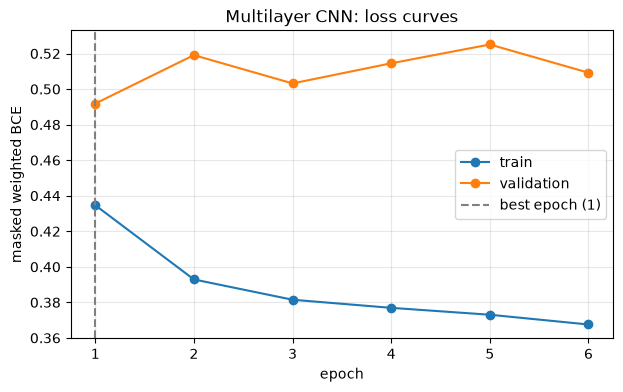

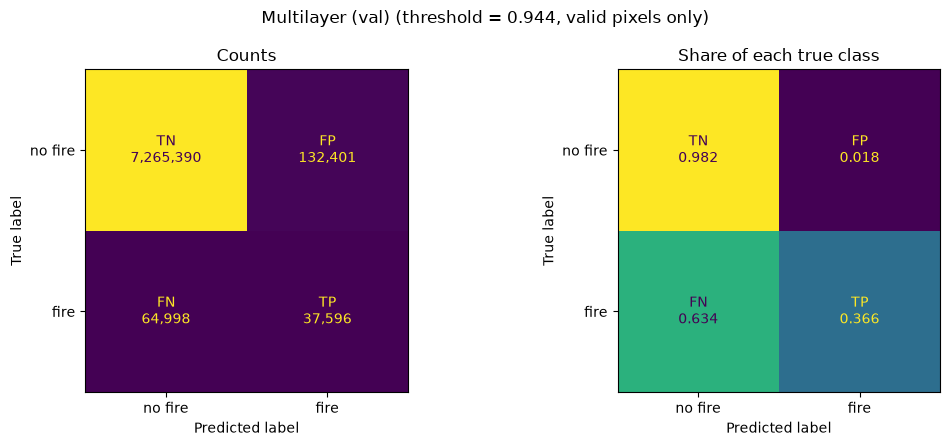

PR-AUC: 0.1559


In [142]:
plot_loss_curves(history_multilayer, 'Multilayer CNN')
plot_confusion(y_true, y_score, best_f1_threshold(y_true, y_score), 'Multilayer (val)')
results.append(summarize('Multilayer CNN', 'val', y_true, y_score, best_f1_threshold(y_true, y_score)))

## Building Model 3 - U-Net CNN

Below the third model is built, which is a U-Net Convolutional Neural Network. The architecture is a standard U-Net for pixel-level predictions for an input of the size 64x64x12. The encoder downsamples the spatial dimensions via `MaxPooling2D` while doubling filter depth via the convolutional block, `conv_block`. This builds up the abstract features while saving each stage's output before pooling. The bottleneck is the most compressed representation of the input. The decoder mirrors the encoder but performs the process in reverse. It upsamples via `UpSampling2D`, concatenating each stage with its corresponding "skip connection" to put the fine spatial detail back into the process. It then runs another convolutional block to blend all the combined features. The final output layer is a 1x1 `Conv2D` layer with no activation and produces raw logits per pixel rather than probabilities. This matches the loss function's expectation of a logit input. 

In [143]:
def conv_block(x, filters, name_prefix):
    """Two 3x3 conv+ReLU layers, same padding,."""
    x = layers.Conv2D(filters, 3, padding='same', activation='relu', name=f'{name_prefix}_conv1')(x)
    x = layers.Conv2D(filters, 3, padding='same', activation='relu', name=f'{name_prefix}_conv2')(x)
    return x

def build_unet(input_shape=(64, 64, 12)):
    inputs = layers.Input(shape=input_shape, name='input')

    # Encoder
    skip1 = conv_block(inputs, 16, 'enc1')           # 64x64x16
    p1 = layers.MaxPooling2D(2, name='pool1')(skip1) # 32x32x16

    skip2 = conv_block(p1, 32, 'enc2')               # 32x32x32
    p2 = layers.MaxPooling2D(2, name='pool2')(skip2) # 16x16x32

    skip3 = conv_block(p2, 64, 'enc3')               # 16x16x64
    p3 = layers.MaxPooling2D(2, name='pool3')(skip3) # 8x8x64

    # Bottleneck
    bottleneck = conv_block(p3, 128, 'bottleneck')   # 8x8x128

    # Decoder
    u3 = layers.UpSampling2D(2, interpolation='bilinear', name='up3')(bottleneck)  # 16x16x128
    u3 = layers.Concatenate(name='concat3')([u3, skip3])                           # 16x16x192
    d3 = conv_block(u3, 64, 'dec3')                                                # 16x16x64

    u2 = layers.UpSampling2D(2, interpolation='bilinear', name='up2')(d3)          # 32x32x64
    u2 = layers.Concatenate(name='concat2')([u2, skip2])                           # 32x32x96
    d2 = conv_block(u2, 32, 'dec2')                                                # 32x32x32

    u1 = layers.UpSampling2D(2, interpolation='bilinear', name='up1')(d2)          # 64x64x32
    u1 = layers.Concatenate(name='concat1')([u1, skip1])                           # 64x64x48
    d1 = conv_block(u1, 16, 'dec1')                                                # 64x64x16

    # Output: linear logits
    outputs = layers.Conv2D(1, 1, padding='same', activation=None, name='output')(d1)  # 64x64x1

    model = Model(inputs=inputs, outputs=outputs, name='unet')
    return model

tf.keras.utils.set_random_seed(SEED)
tf.keras.backend.clear_session()
unet_model = build_unet(input_shape=(64, 64, 12))
unet_model.summary()

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 64, 64,    │          0 │ -                 │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv1 (Conv2D) │ (None, 64, 64,    │      1,744 │ input[0][0]       │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv2 (Conv2D) │ (None, 64, 64,    │      2,320 │ enc1_conv1[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 32, 32,    │          0 │ enc1_conv2[0][0]  │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv1 (Conv2D) │ (None, 32, 32,    │      4,640 │ pool1[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv2 (Conv2D) │ (None, 32, 32,    │      9,248 │ enc2_conv1[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 16, 16,    │          0 │ enc2_conv2[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_conv1 (Conv2D) │ (None, 16, 16,    │     18,496 │ pool2[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_conv2 (Conv2D) │ (None, 16, 16,    │     36,928 │ enc3_conv1[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool3               │ (None, 8, 8, 64)  │          0 │ enc3_conv2[0][0]  │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv1    │ (None, 8, 8, 128) │     73,856 │ pool3[0][0]       │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv2    │ (None, 8, 8, 128) │    147,584 │ bottleneck_conv1… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up3 (UpSampling2D)  │ (None, 16, 16,    │          0 │ bottleneck_conv2… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat3             │ (None, 16, 16,    │          0 │ up3[0][0],        │
│ (Concatenate)       │ 192)              │            │ enc3_conv2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec3_conv1 (Conv2D) │ (None, 16, 16,    │    110,656 │ concat3[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec3_conv2 (Conv2D) │ (None, 16, 16,    │     36,928 │ dec3_conv1[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up2 (UpSampling2D)  │ (None, 32, 32,    │          0 │ dec3_conv2[0][0]

 Total params: 488,593 (1.86 MB)

 Trainable params: 488,593 (1.86 MB)

 Non-trainable params: 0 (0.00 B)

Below, the U-Net model is compiled using the same `masked_weighted_bce` loss function, the Adam optimizer, and a learning rate of 1e-3. It also uses `EarlyStopping` to monitor `val_loss` with a patience of 5 epochs and keeps the best weights saved in a folder in Google Drive.

In [144]:
# Compile the model
unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=masked_weighted_bce
)

# Checkpoint path
unet_checkpoint_path = RUN_DIR + 'unet_best.keras'

checkpoint_cb = ModelCheckpoint(
    filepath=unet_checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

earlystop_cb = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

The model is trained below. Note that it uses the generators created via the `ArraySequence` class created earlier.

In [145]:
# Train the model
history_unet = unet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    callbacks=[checkpoint_cb, earlystop_cb],
    verbose=1
)
pd.DataFrame(history_unet.history).to_csv(RUN_DIR + 'history_unet.csv', index=False)

Epoch 1/20
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.3060
Epoch 1: val_loss improved from None to 0.36706, saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_best.keras

Epoch 1: finished saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_best.keras
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 124s 66ms/step - loss: 0.3060 - val_loss: 0.3671
Epoch 2/20
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 0.2503
Epoch 2: val_loss improved from 0.36706 to 0.30827, saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_best.keras

Epoch 2: finished saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_best.keras
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 128s 69ms/step - loss: 0.2503 - val_loss: 0.3083
Epoch 3/20
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.2401
Epoch 3: val_loss did not improve from 0.30827
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 123s 66ms/step - loss: 0.2401 - val_l

In [146]:
# Load the U-Net checkpoint path
unet_checkpoint_path = RUN_DIR + 'unet_best.keras'
unet_model = tf.keras.models.load_model(
    unet_checkpoint_path,
    custom_objects={'masked_weighted_bce': masked_weighted_bce}
)

# Reconstruct true labels and valid mask from target_val
y_true_full = target_val[..., 0]
valid_mask = target_val[..., 1] > 0

# Get predictions (logits to probabilities)
y_pred_logits = unet_model.predict(X_val, verbose=1, batch_size=8)
y_pred_prob = tf.sigmoid(y_pred_logits[..., 0]).numpy()

# Flatten to valid pixels only
y_true = y_true_full[valid_mask]
y_score = y_pred_prob[valid_mask]

# AUC
unet_auc = roc_auc_score(y_true, y_score)
unet_pr_auc = average_precision_score(y_true, y_score)

print("\n---Model 3 (U-Net CNN) Validation AUC---")
print(f"Model 3 U-Net Validation AUC:         {unet_auc:.4f}")
print(f"U-Net Validation PR-AUC: {unet_pr_auc:.4f}")
print("Model 2 Multilayer CNN Validation AUC: 0.8211 (for comparison)")

  5/235 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step   

E0000 00:00:1793314785.211039 91918165 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step

---Model 3 (U-Net CNN) Validation AUC---
Model 3 U-Net Validation AUC:         0.9368
U-Net Validation PR-AUC: 0.2244
Model 2 Multilayer CNN Validation AUC: 0.8211 (for comparison)


The AUC for Model 3 is once again a large improvement from before, going from 0.8211 in the multi-layer CNN to 0.9303 for the U-Net.

In [147]:
# Calculate metrics
precisions, recalls, thresholds = precision_recall_curve(y_true, y_score)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores[:-1]) 
best_threshold = thresholds[best_idx]

# IoU at that threshold
y_pred_binary = (y_score >= best_threshold).astype(int)
intersection = np.sum((y_pred_binary == 1) & (y_true == 1))
union = np.sum((y_pred_binary == 1) | (y_true == 1))
iou_best = intersection / union

print("\n---Model 3 (U-Net CNN) Validation Metrics at Best Threshold---")
print(f"Best threshold (max F1): {best_threshold:.4f}")
print("At that best threshold:")
print(f"    Precision: {precisions[best_idx]:.4f}")
print(f"    Recall:    {recalls[best_idx]:.4f}")
print(f"    F1:        {f1_scores[best_idx]:.4f}")
print(f"    IoU:       {iou_best:.4f}")


---Model 3 (U-Net CNN) Validation Metrics at Best Threshold---
Best threshold (max F1): 0.9360
At that best threshold:
    Precision: 0.2438
    Recall:    0.4990
    F1:        0.3275
    IoU:       0.1958


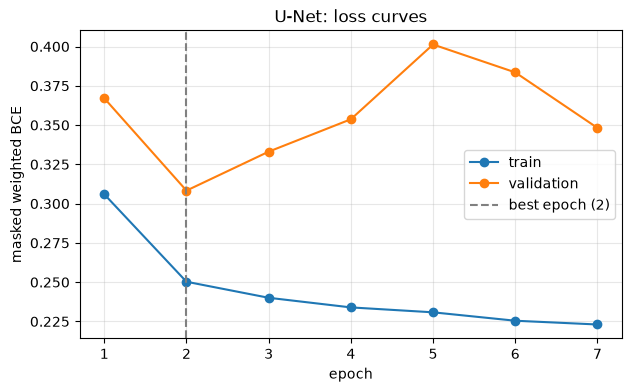

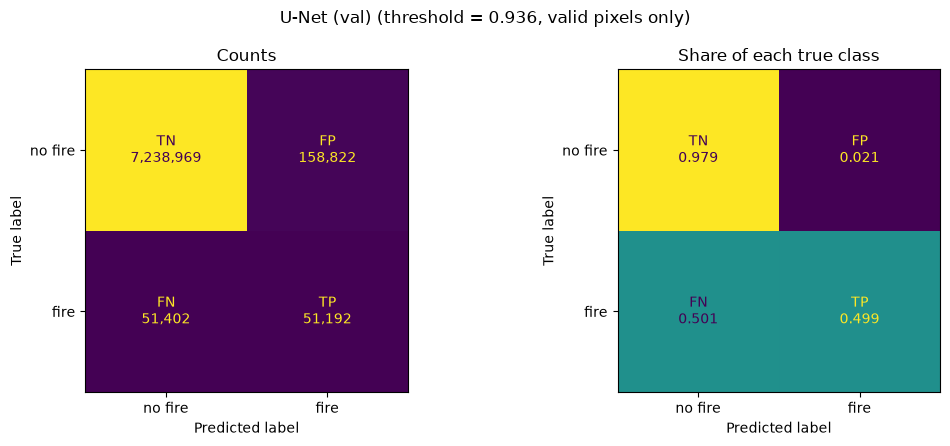

PR-AUC: 0.2244


In [148]:
plot_loss_curves(history_unet, 'U-Net')
plot_confusion(y_true, y_score, best_f1_threshold(y_true, y_score), 'U-Net (val)')
results.append(summarize('U-Net', 'val', y_true, y_score, best_f1_threshold(y_true, y_score)))

The best threshold for this model is 0.9352. At this threshold, the precision, recall, F1, and IoU are all quite moderate. This large gap between these metrics and AUC is potentially due to the severe class imbalance of no-fire/fire pixels. There are probably a lot more false positives than true positives, and this is reflected in the lower metric scores. Because AUC is threshold-independent, it offers the clearest insight into how well the model ranks pixels relative to each other.

## Model 3 (U-Net) Hyperparameter Tuning
This sections contains the hyperparameter tuning done for the U-Net architecture. Two strategies were used: adding a dropout layer and adjusting the learning rate. 

### Adding dropout
For this section of the tuning, one dropout layer in the bottleneck layer was added in the U-Net model. All other hyperparameters stayed exactly the same.

In [149]:
def conv_block_dropout(x, filters, name_prefix, dropout_rate=0.0):
    """Two 3x3 conv+ReLU layers, same padding, optional spatial dropout."""
    x = layers.Conv2D(filters, 3, padding='same', activation='relu', name=f'{name_prefix}_conv1')(x)
    x = layers.Conv2D(filters, 3, padding='same', activation='relu', name=f'{name_prefix}_conv2')(x)
    if dropout_rate > 0:
        x = layers.SpatialDropout2D(dropout_rate, name=f'{name_prefix}_dropout')(x)
    return x

def build_unet_dropout(input_shape=(64, 64, 12)):
    inputs = layers.Input(shape=input_shape, name='input')

    # Encoder
    skip1 = conv_block_dropout(inputs, 16, 'enc1')       # 64x64x16
    p1 = layers.MaxPooling2D(2, name='pool1')(skip1)     # 32x32x16

    skip2 = conv_block_dropout(p1, 32, 'enc2')           # 32x32x32
    p2 = layers.MaxPooling2D(2, name='pool2')(skip2)     # 16x16x32

    skip3 = conv_block_dropout(p2, 64, 'enc3')           # 16x16x64
    p3 = layers.MaxPooling2D(2, name='pool3')(skip3)     # 8x8x64

    # Bottleneck (dropout added here)
    bottleneck = conv_block_dropout(p3, 128, 'bottleneck', dropout_rate=0.15)  # 8x8x128

    # Decoder
    u3 = layers.UpSampling2D(2, interpolation='bilinear', name='up3')(bottleneck)  # 16x16x128
    u3 = layers.Concatenate(name='concat3')([u3, skip3])                           # 16x16x192
    d3 = conv_block_dropout(u3, 64, 'dec3')                                        # 16x16x64

    u2 = layers.UpSampling2D(2, interpolation='bilinear', name='up2')(d3)          # 32x32x64
    u2 = layers.Concatenate(name='concat2')([u2, skip2])                           # 32x32x96
    d2 = conv_block_dropout(u2, 32, 'dec2')                                        # 32x32x32

    u1 = layers.UpSampling2D(2, interpolation='bilinear', name='up1')(d2)          # 64x64x32
    u1 = layers.Concatenate(name='concat1')([u1, skip1])                           # 64x64x48
    d1 = conv_block_dropout(u1, 16, 'dec1')                                        # 64x64x16

    # Output: linear logits
    outputs = layers.Conv2D(1, 1, padding='same', activation=None, name='output')(d1)  # 64x64x1

    model = Model(inputs=inputs, outputs=outputs, name='unet')
    return model


tf.keras.utils.set_random_seed(SEED)
tf.keras.backend.clear_session()
unet_model_dropout = build_unet_dropout(input_shape=(64, 64, 12))
unet_model_dropout.summary()

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 64, 64,    │          0 │ -                 │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv1 (Conv2D) │ (None, 64, 64,    │      1,744 │ input[0][0]       │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv2 (Conv2D) │ (None, 64, 64,    │      2,320 │ enc1_conv1[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 32, 32,    │          0 │ enc1_conv2[0][0]  │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv1 (Conv2D) │ (None, 32, 32,    │      4,640 │ pool1[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv2 (Conv2D) │ (None, 32, 32,    │      9,248 │ enc2_conv1[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 16, 16,    │          0 │ enc2_conv2[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_conv1 (Conv2D) │ (None, 16, 16,    │     18,496 │ pool2[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_conv2 (Conv2D) │ (None, 16, 16,    │     36,928 │ enc3_conv1[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool3               │ (None, 8, 8, 64)  │          0 │ enc3_conv2[0][0]  │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv1    │ (None, 8, 8, 128) │     73,856 │ pool3[0][0]       │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv2    │ (None, 8, 8, 128) │    147,584 │ bottleneck_conv1… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_dropout  │ (None, 8, 8, 128) │          0 │ bottleneck_conv2… │
│ (SpatialDropout2D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up3 (UpSampling2D)  │ (None, 16, 16,    │          0 │ bottleneck_dropo… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat3             │ (None, 16, 16,    │          0 │ up3[0][0],        │
│ (Concatenate)       │ 192)              │            │ enc3_conv2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec3_conv1 (Conv2D) │ (None, 16, 16,    │    110,656 │ concat3[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec3_conv2 (Conv2D) │ (None, 16, 16,    │     36,928 │ dec3_conv1[0][0]

 Total params: 488,593 (1.86 MB)

 Trainable params: 488,593 (1.86 MB)

 Non-trainable params: 0 (0.00 B)

In [150]:
unet_model_dropout.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=masked_weighted_bce
)

# New checkpoint path
unet_dropout_checkpoint_path = RUN_DIR + 'unet_dropout_best.keras'

checkpoint_cb = ModelCheckpoint(
    filepath=unet_dropout_checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

earlystop_cb = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

In [151]:
history_unet_dropout = unet_model_dropout.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    callbacks=[checkpoint_cb, earlystop_cb],
    verbose=1
)
pd.DataFrame(history_unet_dropout.history).to_csv(RUN_DIR + 'history_unet_dropout.csv', index=False)

Epoch 1/20
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 0.3145
Epoch 1: val_loss improved from None to 0.35572, saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_dropout_best.keras

Epoch 1: finished saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_dropout_best.keras
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 121s 64ms/step - loss: 0.3145 - val_loss: 0.3557
Epoch 2/20
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 0.2557
Epoch 2: val_loss did not improve from 0.35572
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 120s 64ms/step - loss: 0.2557 - val_loss: 0.3737
Epoch 3/20
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 0.2463
Epoch 3: val_loss improved from 0.35572 to 0.35049, saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_dropout_best.keras

Epoch 3: finished saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_dropout_best.keras
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 120s 

In [152]:
# Load the saved U-Net with dropout checkpoint
unet_dropout_checkpoint_path = RUN_DIR + 'unet_dropout_best.keras'
unet_model_dropout = tf.keras.models.load_model(
    unet_dropout_checkpoint_path,
    custom_objects={'masked_weighted_bce': masked_weighted_bce}
)

# Reconstruct true labels and valid mask from target_val
y_true_full = target_val[..., 0]
valid_mask = target_val[..., 1] > 0

# Get predictions (logits to probabilities)
y_pred_logits_dropout = unet_model_dropout.predict(X_val, verbose=1, batch_size=8)
y_pred_prob_dropout = tf.sigmoid(y_pred_logits_dropout[..., 0]).numpy()

# Flatten to valid pixels only
y_true = y_true_full[valid_mask]
y_score_dropout = y_pred_prob_dropout[valid_mask]

# AUC
unet_dropout_auc = roc_auc_score(y_true, y_score_dropout)
unet_dropout_pr_auc = average_precision_score(y_true, y_score_dropout)

print("\n---U-Net CNN with Dropout Validation AUC---")
print(f"U-Net CNN with Dropout Validation AUC:       {unet_dropout_auc:.4f}")
print(f"U-Net with Dropout Validation PR-AUC: {unet_dropout_pr_auc:.4f}")
print("Model 3 U-Net without Dropout Validation AUC: 0.9303 (for comparison)")

  1/235 ━━━━━━━━━━━━━━━━━━━━ 1:29 381ms/step

E0000 00:00:1793316527.790673 91918165 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step

---U-Net CNN with Dropout Validation AUC---
U-Net CNN with Dropout Validation AUC:       0.9357
U-Net with Dropout Validation PR-AUC: 0.2693
Model 3 U-Net without Dropout Validation AUC: 0.9303 (for comparison)


In [153]:
# Calculate metrics
precisions, recalls, thresholds = precision_recall_curve(y_true, y_score_dropout)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores[:-1])
best_threshold_dropout = thresholds[best_idx]

# IoU at that threshold
y_pred_binary_dropout = (y_score_dropout >= best_threshold_dropout).astype(int)
intersection = np.sum((y_pred_binary_dropout == 1) & (y_true == 1))
union = np.sum((y_pred_binary_dropout == 1) | (y_true == 1))
iou_dropout = intersection / union

print("\n---U-Net with Dropout Validation Metrics at Best Threshold---")
print(f"Best threshold (max F1): {best_threshold_dropout:.4f}")
print("At that best threshold:")
print(f"    Precision: {precisions[best_idx]:.4f}")
print(f"    Recall:    {recalls[best_idx]:.4f}")
print(f"    F1:        {f1_scores[best_idx]:.4f}")
print(f"    IoU:       {iou_dropout:.4f}")


---U-Net with Dropout Validation Metrics at Best Threshold---
Best threshold (max F1): 0.9648
At that best threshold:
    Precision: 0.2937
    Recall:    0.4333
    F1:        0.3501
    IoU:       0.2122


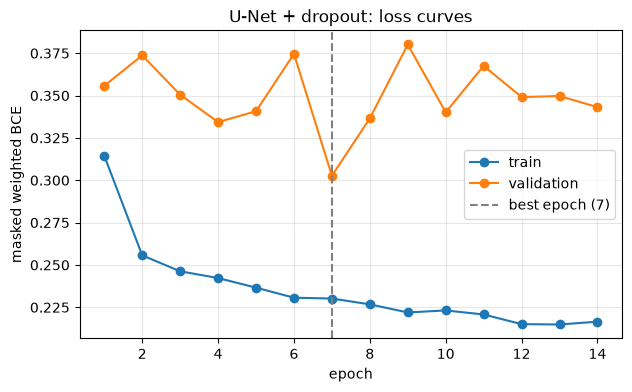

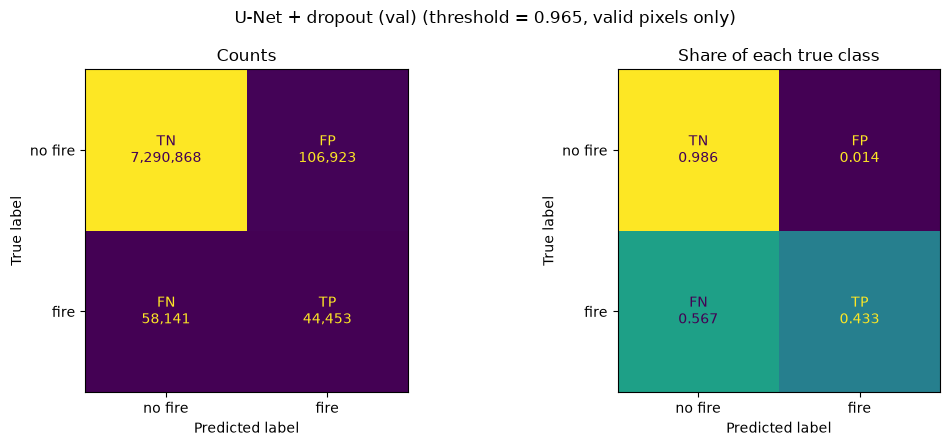

PR-AUC: 0.2693


In [154]:
plot_loss_curves(history_unet_dropout, 'U-Net + dropout')
plot_confusion(y_true, y_score_dropout, best_f1_threshold(y_true, y_score_dropout), 'U-Net + dropout (val)')
results.append(summarize('U-Net + dropout', 'val', y_true, y_score_dropout, best_f1_threshold(y_true, y_score_dropout)))

The AUC for the U-Net with dropout, 0.9239, did not increase from the U-Net without dropout, 0.9303. Due to this, we remove the dropout layer and move forward with tuning.

### Tuning Learning Rate

For this section, we decreased the learning rate from 1e-3 to 3e-4 (in the U-Net model *without* dropout). All other hyperparameters stayed exactly the same. The function below, `run_lr_experiment()` can be used to test various learning rates.

In [155]:
def run_lr_experiment(learning_rate, run_name):
    tf.keras.utils.set_random_seed(SEED)
    tf.keras.backend.clear_session()
    model = build_unet(input_shape=(64, 64, 12))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=masked_weighted_bce
    )

    checkpoint_path = f'{RUN_DIR}unet_{run_name}_best.keras'
    checkpoint_cb = ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
    earlystop_cb = EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=20,
        callbacks=[checkpoint_cb, earlystop_cb],
        verbose=1
    )
    return model, history

In [156]:
unet_lr_low, history_lr_low = run_lr_experiment(learning_rate=3e-4, run_name='lr3e4')

pd.DataFrame(history_lr_low.history).to_csv(RUN_DIR + 'history_lr_low.csv', index=False)

Epoch 1/20
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 0.3394
Epoch 1: val_loss improved from None to 0.34253, saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_lr3e4_best.keras

Epoch 1: finished saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_lr3e4_best.keras
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 125s 66ms/step - loss: 0.3394 - val_loss: 0.3425
Epoch 2/20
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 0.2520
Epoch 2: val_loss did not improve from 0.34253
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 119s 64ms/step - loss: 0.2520 - val_loss: 0.3799
Epoch 3/20
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.2378
Epoch 3: val_loss improved from 0.34253 to 0.33895, saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_lr3e4_best.keras

Epoch 3: finished saving model to /Users/jordanagresti/Desktop/Data Projects/Wildfire/runs/team/unet_lr3e4_best.keras
1873/1873 ━━━━━━━━━━━━━━━━━━━━ 119s 63ms/ste

In [157]:
# Load the saved U-Net with checkpoint (lower loss, lr=3e-4)
unet_lr_low_checkpoint_path = RUN_DIR + 'unet_lr3e4_best.keras'
unet_lr_low = tf.keras.models.load_model(
    unet_lr_low_checkpoint_path,
    custom_objects={'masked_weighted_bce': masked_weighted_bce}
)

valid_mask = target_val[..., 1] > 0
y_true = target_val[..., 0][valid_mask]

y_pred_logits_lr = unet_lr_low.predict(X_val, verbose=1, batch_size=8)
y_pred_prob_lr = tf.sigmoid(y_pred_logits_lr[..., 0]).numpy()
y_score_lr = y_pred_prob_lr[valid_mask]

unet_lr_auc = roc_auc_score(y_true, y_score_lr)
unet_lr_pr_auc = average_precision_score(y_true, y_score_lr)

print("\n---U-Net (lr=3e-4) Validation AUC---")
print(f"U-Net (lr=3e-4) Validation AUC:          {unet_lr_auc:.4f}")
print(f"U-Net (lr=3e-4) Validation PR-AUC: {unet_lr_pr_auc:.4f}")
print("U-Net (original, lr=1e-3) Validation AUC: 0.9303 (for comparison)")

  4/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step  

E0000 00:00:1793317873.561299 91918165 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step

---U-Net (lr=3e-4) Validation AUC---
U-Net (lr=3e-4) Validation AUC:          0.9336
U-Net (lr=3e-4) Validation PR-AUC: 0.2342
U-Net (original, lr=1e-3) Validation AUC: 0.9303 (for comparison)


The U-Net with a smaller learning rate produced an AUC of 0.9341, which is an improvement from the AUC of model with a learning rate of 1e-3, 0.9303. As such, this is an optimal model performance, and this is our final model. Extra metrics for this model are displayed below, as well as the actual precision-recall curve.

 10/235 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step

E0000 00:00:1793317880.580266 91918165 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step

---U-Net (lr=3e-4) Validation Metrics at Best Threshold---
Best threshold (max F1): 0.9020
At that best threshold:
    Precision: 0.2654
    Recall:    0.4732
    F1:        0.3401
    IoU:       0.2049


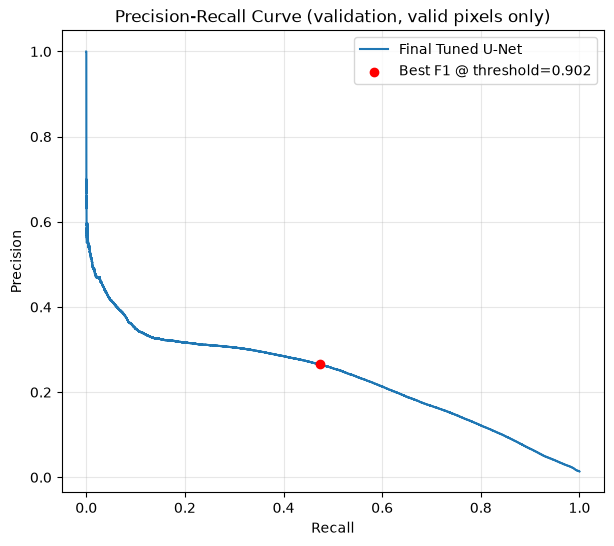

In [158]:
y_pred_logits_lr = unet_lr_low.predict(X_val, verbose=1, batch_size=8)
y_pred_prob_lr = tf.sigmoid(y_pred_logits_lr[..., 0]).numpy()
y_score_lr = y_pred_prob_lr[valid_mask]

precisions, recalls, thresholds = precision_recall_curve(y_true, y_score_lr)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores[:-1])
best_threshold_lr = thresholds[best_idx]

y_pred_binary_lr = (y_score_lr >= best_threshold_lr).astype(int)
intersection = np.sum((y_pred_binary_lr == 1) & (y_true == 1))
union = np.sum((y_pred_binary_lr == 1) | (y_true == 1))
iou_lr = intersection / union

print("\n---U-Net (lr=3e-4) Validation Metrics at Best Threshold---")
print(f"Best threshold (max F1): {best_threshold_lr:.4f}")
print("At that best threshold:")
print(f"    Precision: {precisions[best_idx]:.4f}")
print(f"    Recall:    {recalls[best_idx]:.4f}")
print(f"    F1:        {f1_scores[best_idx]:.4f}")
print(f"    IoU:       {iou_lr:.4f}")

# Plot the PR curve
plt.figure(figsize=(7,6))
plt.plot(recalls, precisions, label='Final Tuned U-Net')
plt.scatter(recalls[best_idx], precisions[best_idx], color='red', zorder=5,
            label=f'Best F1 @ threshold={best_threshold_lr:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (validation, valid pixels only)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

This Precision-Recall curve has a few insights. The curve starts near precision=1.0 and recall=0.0, drops steeply, then declines more gradually as recall increases towards 1.0. The shape of this curve reflects that the model confidently ranks fire pixels. As the threshold to capture more true fire pixels is lowered, the precision falls off. Going from a precision of near 1.0 to near 0.4 within the first 0.1-0.15 of recall reflects the class imbalance. 

The red dot marks the best F1 value at a threshold of 0.9103. This F1 score is maximized at a precision of 0.2715 and a recall of 0.4695 and is the model's "best balanced" operating point.

Overall, the curve makes it clear that there is no threshold that simultaneously gives high precision and high recall, which is expected given the class imbalance.

Below, the probability distribution of valid pixels is displayed. There is a small bimodal shape to this distribution (two peaks on either side of the plot), which confirms that the model is confidently sorting most pixels into "probably no-fire" or "probably fire" rather than not picking either.

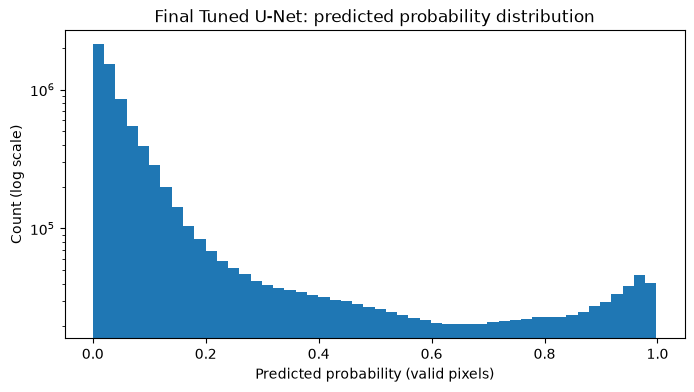

Median predicted prob: 0.0418
Mean predicted prob: 0.1313
% of valid pixels with prob >= 0.5: 8.56%


In [159]:
# Look at the probability distribution for the valid pixels
plt.figure(figsize=(8,4))
plt.hist(y_score_lr, bins=50)
plt.yscale('log')
plt.xlabel('Predicted probability (valid pixels)')
plt.ylabel('Count (log scale)')
plt.title('Final Tuned U-Net: predicted probability distribution')
plt.show()

print(f"Median predicted prob: {np.median(y_score_lr):.4f}")
print(f"Mean predicted prob: {np.mean(y_score_lr):.4f}")
print(f"% of valid pixels with prob >= 0.5: {(y_score_lr >= 0.5).mean()*100:.2f}%")

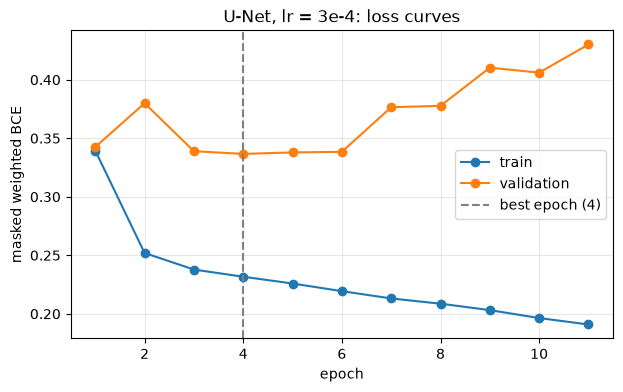

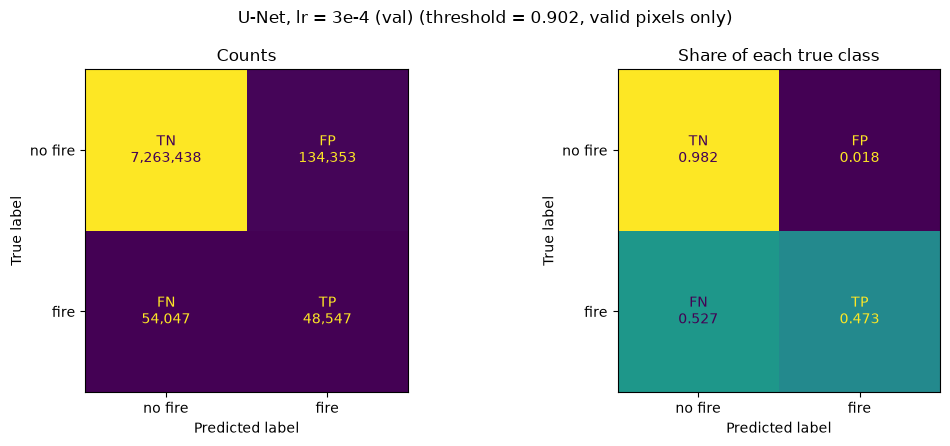

PR-AUC: 0.2342


In [160]:
plot_loss_curves(history_lr_low, 'U-Net, lr = 3e-4')
plot_confusion(y_true, y_score_lr, best_threshold_lr, 'U-Net, lr = 3e-4 (val)')
results.append(summarize('U-Net lr 3e-4', 'val', y_true, y_score_lr, best_threshold_lr))

## Evaluating the Model 

This sections evaluates the best model (U-Net with lower learning rate of 3e-4) on the test data.

In [161]:
# Load the saved best checkpoint from the lr=3e-4 run
unet_lr_checkpoint_path = RUN_DIR + '/unet_lr3e4_best.keras'
unet_test_model = tf.keras.models.load_model(
    unet_lr_checkpoint_path,
    custom_objects={'masked_weighted_bce': masked_weighted_bce}
)

# Reconstruct true labels and valid mask from target_test
y_true_full_test = target_test[..., 0]
valid_mask_test = target_test[..., 1] > 0

# Get predictions from the checkpoint
y_pred_logits_test = unet_test_model.predict(X_test, verbose=1, batch_size=8)
y_pred_prob_test = tf.sigmoid(y_pred_logits_test[..., 0]).numpy()

# Flatten to valid pixels only
y_true_test = y_true_full_test[valid_mask_test]
y_score_test = y_pred_prob_test[valid_mask_test]

# AUC
unet_test_auc = roc_auc_score(y_true_test, y_score_test)
unet_test_pr_auc = average_precision_score(y_true_test, y_score_test)

# Precision/Recall/F1 (using a threshold of 0.9103)
y_pred_binary_test = (y_score_test >= best_threshold_lr).astype(int)

precision_test = np.sum((y_pred_binary_test == 1) & (y_true_test == 1)) / (np.sum(y_pred_binary_test == 1) + 1e-10)
recall_test = np.sum((y_pred_binary_test == 1) & (y_true_test == 1)) / (np.sum(y_true_test == 1) + 1e-10)
f1_test = 2 * precision_test * recall_test / (precision_test + recall_test + 1e-10)

intersection_test = np.sum((y_pred_binary_test == 1) & (y_true_test == 1))
union_test = np.sum((y_pred_binary_test == 1) | (y_true_test == 1))
iou_test = intersection_test / union_test

print("\n---U-Net (lr=3e-4) AUC Metrics---")
print(f"U-Net (lr=3e-4) Test AUC:      {unet_test_auc:.4f}")
print(f"U-Net Test PR-AUC: {unet_test_pr_auc:.4f}")
print("U-Net (lr=3e-4) Validation AUC: 0.9341 (for comparison)")


print("\n---U-Net (lr=3e-4) Other Test Metrics at Validation Best Threshold---")
print(f"    Precision: {precision_test:.4f}")
print(f"    Recall:    {recall_test:.4f}")
print(f"    F1:        {f1_test:.4f}")
print(f"    IoU:       {iou_test:.4f}")

  5/212 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step  

E0000 00:00:1793317893.726181 91918165 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


212/212 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step

---U-Net (lr=3e-4) AUC Metrics---
U-Net (lr=3e-4) Test AUC:      0.9418
U-Net Test PR-AUC: 0.2986
U-Net (lr=3e-4) Validation AUC: 0.9341 (for comparison)

---U-Net (lr=3e-4) Other Test Metrics at Validation Best Threshold---
    Precision: 0.2801
    Recall:    0.5920
    F1:        0.3802
    IoU:       0.2347


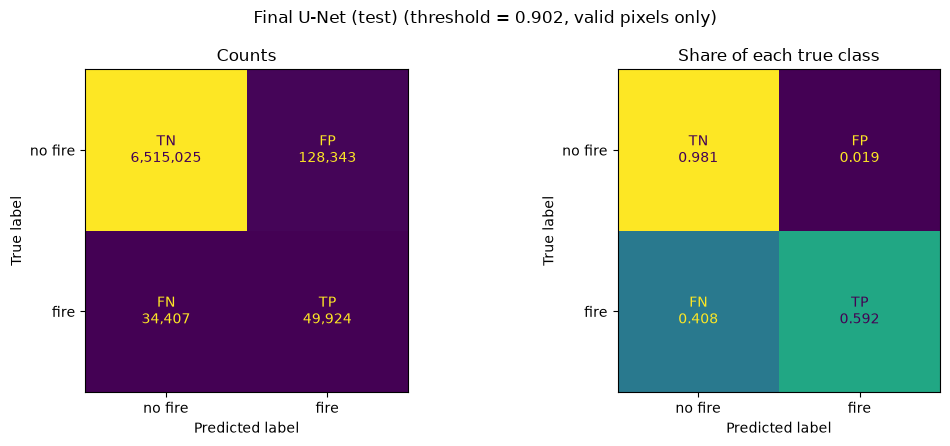

PR-AUC: 0.2986


In [162]:
plot_confusion(y_true_test, y_score_test, best_threshold_lr, 'Final U-Net (test)')
results.append(summarize('U-Net lr 3e-4', 'test', y_true_test, y_score_test, best_threshold_lr))

In [163]:
results_df = pd.DataFrame(results)
results_df.to_csv(RUN_DIR + 'results.csv', index=False)
display(results_df.round(4))

,model,split,threshold,pr_auc,roc_auc,precision,recall,f1,iou
0,Baseline,val,0.9354,0.0846,0.7363,0.2860,0.1803,0.2212,0.1243
1,Multilayer CNN,val,0.9441,0.1559,0.8427,0.2212,0.3665,0.2758,0.1600
2,U-Net,val,0.9360,0.2244,0.9368,0.2438,0.4990,0.3275,0.1958
3,U-Net + dropout,val,0.9648,0.2693,0.9357,0.2937,0.4333,0.3501,0.2122
4,U-Net lr 3e-4,val,0.9020,0.2342,0.9336,0.2654,0.4732,0.3401,0.2049
5,U-Net lr 3e-4,test,0.9020,0.2986,0.9418,0.2801,0.5920,0.3802,0.2347


### Final Discussion
The Test AUC of 0.9365 appears to be better than the Validation AUC of 0.9341. So, the test data outperformed the validation data, which is not very common. This could be due to distributional variance given the no-fire/fire class imbalance. 

Another potential reason for this could be due to how the train/val/test splits were made. Because our data source has ready-made train/val/test sets, we aren't familiar with how this split happened. It is possible that the split wasn't fully random with respect to time and geography.

Overall, the model appears to perform quite well. It optimally predicts next-day fire spread given the AUC metric.